# Model Development, Part I: preliminary checks for the candidate models

These are quick checks that turn assumptions into evidence. **Prediction checks use the training eras only**
(IMPACT341/410/468); the IMPACT505 test era stays untouched. No candidate is trained or compared here.

Data: `../data/processed/` built by `scripts/build_datasets.py` (see `REVIEW_LOG.md` for the six review passes).

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.api as sm
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test
from IPython.display import display

sys.path.insert(0, "../src")
from chordsurv.config import HORIZON_MONTHS

DATA = Path("../data/processed")
FIG = Path("../reports/part1/figures"); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 180)
INK2, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.labelcolor": INK2, "legend.frameon": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left"})

groups = json.loads((DATA / "feature_groups.json").read_text())
landmark = pd.read_parquet(DATA / "landmark.parquet")
genomics = pd.read_parquet(DATA / "genomics.parquet")
patients = pd.read_parquet(DATA / "patients.parquet")
causal = pd.read_parquet(DATA / "causal.parquet")
train = landmark[~landmark.test_era].join(genomics)
print(f"training landmark patients: {len(train):,} (deaths {train.event.sum():,}); test era kept aside: {landmark.test_era.sum():,}")

training landmark patients: 15,595 (deaths 7,531); test era kept aside: 6,003


## 1. Prediction (landmark at 6 months, 12-month horizon), training eras only
### 1.1 The target: remaining survival from the landmark, censored

In [2]:
h = np.select([train.event.eq(1) & train.time.le(HORIZON_MONTHS), train.time.gt(HORIZON_MONTHS)],
              ["died within 12 months", "known alive at 12 months"], default="censored before 12 months")
display(pd.Series(h).value_counts().to_frame("patients"))
rows = {}
for ct, g in train.groupby("cancer_type"):
    km = KaplanMeierFitter().fit(g.time, g.event)
    rows[ct] = {"patients": len(g), "deaths": int(g.event.sum()), "risk of death by 12 months": 1 - km.predict(HORIZON_MONTHS)}
pd.DataFrame(rows).T.sort_values("risk of death by 12 months").style.format({"patients": "{:,.0f}", "deaths": "{:,.0f}", "risk of death by 12 months": "{:.1%}"})

,patients
known alive at 12 months,12275
died within 12 months,2995
censored before 12 months,325


,patients,deaths,risk of death by 12 months
Prostate Cancer,"2,050",763,11.8%
Breast Cancer,"3,932","1,515",13.8%
Colorectal Cancer,"3,367","1,579",17.0%
Non-Small Cell Lung Cancer,"4,678","2,484",22.7%
Pancreatic Cancer,"1,568","1,190",38.6%


### 1.2 Size of the feature space vs the number of events
Planned preprocessing (done inside each CV fold in Part II):
- **Genes:** keep those mutated or altered in ≥ 1% of training patients.
- **Categorical:** one-hot encode, grouping rare categories.
- **Missing values:** a missing-value indicator for each feature with missing values. The exception is `never_smoker`, which is imputed without one (REVIEW_LOG 3.1).

In [3]:
clinical = groups["static"] + groups["day0"] + groups["landmark"] + groups["window"]
categorical = [c for c in clinical if train[c].dtype == object]
numeric = [c for c in clinical if c not in categorical]
onehot = sum(min(train[c].nunique(), 15) for c in categorical)
genomic_prev = train[groups["genomic"]].mean()
kept_genomic = genomic_prev[genomic_prev >= 0.01].index
indicators = sum(train[c].isna().any() for c in numeric if c not in groups["impute_without_indicator"])
p = len(numeric) + onehot + len(kept_genomic) + indicators
print(f"numeric clinical {len(numeric)}, one-hot columns ~{onehot}, missing indicators {indicators}, genomic kept {len(kept_genomic)} of {len(groups['genomic'])}")
print(f"p ~ {p} (+{len(groups['intensity'])} count features in the MSK-specific version); deaths in training {train.event.sum():,} -> ~{train.event.sum() / p:.0f} events per feature")
print(f"share of genomic indicators with prevalence < 5%: {(genomic_prev[kept_genomic] < 0.05).mean():.0%}")

numeric clinical 95, one-hot columns ~51, missing indicators 38, genomic kept 277 of 1529
p ~ 461 (+3 count features in the MSK-specific version); deaths in training 7,531 -> ~16 events per feature
share of genomic indicators with prevalence < 5%: 94%


### 1.3 Proportional hazards: does a feature's effect stay constant over time?
The Cox model (and gradient boosting with a Cox loss) assumes that each feature multiplies the hazard by the same factor at every time. Two checks on a compact set of strong features:
1. The Schoenfeld-residual test.
2. The hazard ratio estimated separately for the first 6 months after the landmark and for later months.

In [4]:
def compact_design(d):
    X = pd.DataFrame(index=d.index)
    for ct in ["Colorectal Cancer", "Breast Cancer", "Prostate Cancer", "Pancreatic Cancer"]:
        X["ct_" + ct.split()[0].lower()] = d.cancer_type.eq(ct).astype(float)
    X["stage4"] = d.stage_dx.eq("Stage 4").astype(float)
    for c in ["lm_ecog", "win_prog_max"]:
        X[c] = d[c].fillna(train[c].median()); X[c + "_missing"] = d[c].isna().astype(float)
    for c in ["win_n_new_sites", "lm_n_sites", "win_on_systemic_tx_at_landmark", "pre_tx_any", "mut_TP53", "mut_KRAS"]:
        X[c] = d[c].fillna(0)
    X["log_tmb"] = np.log1p(d.tmb)
    return X

X = compact_design(train)
df = X.assign(time=train.time, event=train.event)
cph = CoxPHFitter(penalizer=0.001).fit(df, "time", "event")
ph = proportional_hazard_test(cph, df, time_transform="rank").summary[["test_statistic", "p"]]

def piecewise_hr(cut=6):
    early = df.assign(event=df.event.where(df.time <= cut, 0), time=df.time.clip(upper=cut))
    late = df[df.time > cut].assign(time=lambda d: d.time - cut)
    fit = lambda d: CoxPHFitter(penalizer=0.001).fit(d, "time", "event").hazard_ratios_
    return pd.DataFrame({"HR months 0-6 after landmark": fit(early), "HR after month 6": fit(late)})

pw = piecewise_hr()
table = ph.join(pw).sort_values("test_statistic", ascending=False)
table.head(10).style.format({"test_statistic": "{:.0f}", "p": "{:.1e}", "HR months 0-6 after landmark": "{:.2f}", "HR after month 6": "{:.2f}"})

,test_statistic,p,HR months 0-6 after landmark,HR after month 6
win_on_systemic_tx_at_landmark,266,6.6e-60,0.46,1.21
lm_ecog,111,6.7e-26,1.97,1.12
win_prog_max,99,2.7e-23,5.79,2.59
lm_ecog_missing,29,6.8e-08,0.71,0.84
ct_breast,22,2.1e-06,1.07,0.82
ct_colorectal,21,3.6e-06,0.64,0.89
lm_n_sites,21,3.9e-06,1.27,1.19
win_n_new_sites,18,2.3e-05,1.11,1.04
win_prog_max_missing,9,2.2e-03,0.77,0.53
mut_TP53,9,3.1e-03,1.45,1.40


### 1.4 Interactions: does the same feature mean the same thing in every cancer?
A Cox model is fitted per cancer type on the same compact features (training eras). If the hazard ratios differ a lot, a single additive model needs explicit cancer-type interactions, while trees find them by themselves.

cancer_type,Breast Cancer,Colorectal Cancer,Non-Small Cell Lung Cancer,Pancreatic Cancer,Prostate Cancer
feature,,,,,
lm_ecog,1.34,1.29,1.45,1.53,1.55
mut_KRAS,1.33,1.17,1.08,2.61,1.37
mut_TP53,1.34,1.03,1.20,1.35,1.73
win_n_new_sites,1.08,1.06,1.06,1.10,0.96
win_on_systemic_tx_at_landmark,0.57,1.36,0.81,0.91,1.51
win_prog_max,4.40,3.12,2.38,2.19,3.67


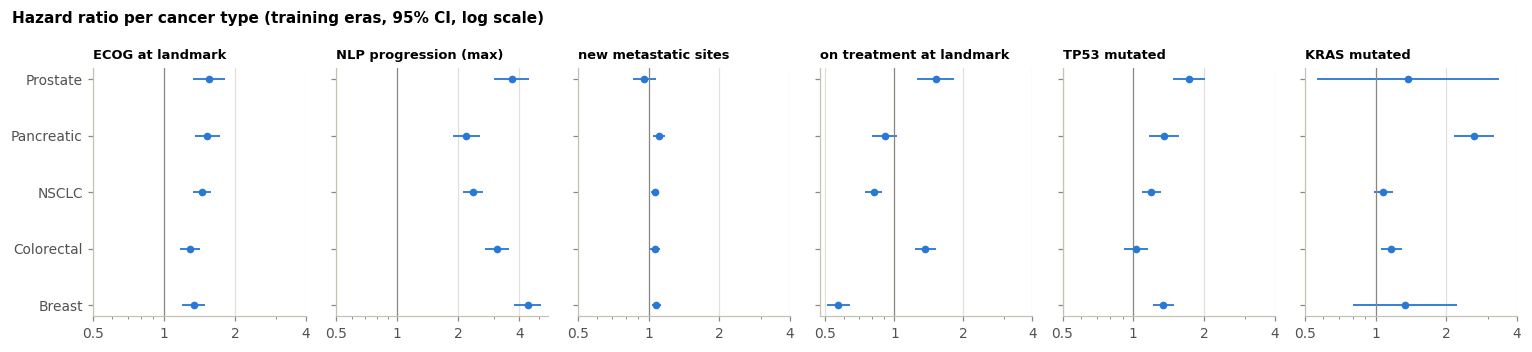

In [5]:
FEATS = ["lm_ecog", "win_prog_max", "win_n_new_sites", "win_on_systemic_tx_at_landmark", "mut_TP53", "mut_KRAS"]
LABEL = {"lm_ecog": "ECOG at landmark", "win_prog_max": "NLP progression (max)", "win_n_new_sites": "new metastatic sites",
         "win_on_systemic_tx_at_landmark": "on treatment at landmark", "mut_TP53": "TP53 mutated", "mut_KRAS": "KRAS mutated"}
per_type = {}
for ct, g in train.groupby("cancer_type"):
    Xg = compact_design(g).drop(columns=[c for c in X.columns if c.startswith("ct_")])
    fit = CoxPHFitter(penalizer=0.001).fit(Xg.assign(time=g.time, event=g.event), "time", "event")
    s = fit.summary.loc[FEATS]
    per_type[ct] = pd.DataFrame({"HR": np.exp(s["coef"]), "lo": np.exp(s["coef lower 95%"]), "hi": np.exp(s["coef upper 95%"])})
hr = pd.concat(per_type, names=["cancer_type", "feature"]).reset_index()
display(hr.pivot(index="feature", columns="cancer_type", values="HR").round(2))

fig, axes = plt.subplots(1, len(FEATS), figsize=(14, 3.2), sharey=True)
order = list(per_type)
for ax, f in zip(axes, FEATS):
    d = hr[hr.feature.eq(f)].set_index("cancer_type").reindex(order)
    y = np.arange(len(d))
    ax.errorbar(d.HR, y, xerr=[d.HR - d.lo, d.hi - d.HR], fmt="o", color=SLOT[0], markersize=4, elinewidth=1.2)
    ax.axvline(1, color=MUTED, linewidth=0.8)
    ax.set_xscale("log"); ax.set_title(LABEL[f], fontsize=8.5); ax.grid(axis="y", visible=False)
    ax.set_xticks([0.5, 1, 2, 4]); ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_yticks(y, [o.replace(" Cancer", "").replace("Non-Small Cell Lung", "NSCLC") for o in order])
fig.suptitle("Hazard ratio per cancer type (training eras, 95% CI, log scale)", x=0.01, ha="left", fontweight="bold", fontsize=10)
plt.tight_layout(); fig.savefig(FIG / "interactions.png", dpi=200); plt.show()

## 2. Inference (D1): 24-month survival from first sequencing, by cancer type
The estimand is S_c(24), so the method is the Kaplan–Meier estimator with Greenwood (log-log) CIs. The checks:
- **Censoring by era**, and an era-weighted estimate: does era-dependent censoring bias the pooled estimate?
- **Era-stratified estimates:** is the quantity stable over time?

In [6]:
rows = {}
for ct, g in patients.groupby("cancer_type"):
    km = KaplanMeierFitter().fit(g.os_months, g.event)
    ci = km.confidence_interval_survival_function_; i = ci.index[ci.index <= 24].max()
    eras = {e: KaplanMeierFitter().fit(gg.os_months, gg.event).predict(24) for e, gg in g.groupby("era") if len(gg) >= 30}
    w = g.era.value_counts(normalize=True).reindex(list(eras))
    rows[ct] = {"S(24)": km.predict(24), "lower": ci.loc[i].iloc[0], "upper": ci.loc[i].iloc[1],
                "era-weighted": sum(eras[e] * w[e] for e in eras) / w.sum(),
                **{f"S(24) {e}": v for e, v in eras.items()}}
pd.DataFrame(rows).T.style.format("{:.1%}")

,S(24),lower,upper,era-weighted,S(24) IMPACT341,S(24) IMPACT410,S(24) IMPACT468,S(24) IMPACT505
Breast Cancer,75.8%,74.6%,77.0%,75.9%,56.0%,67.4%,79.5%,77.7%
Colorectal Cancer,71.4%,70.1%,72.7%,71.8%,53.4%,65.8%,72.0%,76.2%
Non-Small Cell Lung Cancer,61.0%,59.9%,62.1%,61.4%,38.2%,58.2%,62.4%,64.9%
Pancreatic Cancer,38.8%,37.0%,40.7%,38.6%,47.3%,42.4%,37.7%,37.9%
Prostate Cancer,79.5%,78.0%,81.0%,79.6%,75.7%,74.0%,80.2%,82.2%


## 3. Causal question: overlap and balance before any outcome analysis
Eligible: stage 4 NSCLC of conventional histology, no EGFR/ALK driver, untreated before sequencing, first regimen within 60 days, IMPACT468/505 eras.
- **Propensity score:** logistic regression on pre-specified confounders measured at treatment start.
- **Checks:** overlap, and covariate balance before and after stabilised inverse-probability weighting.
- No survival outcome is looked at here.

eligible: 656 | arms: {'immunotherapy': 470, 'chemotherapy': 186}
propensity model converged: True in 6 iterations
propensity range: treated [0.33, 0.98], chemotherapy [0.19, 0.95] | outside [0.05, 0.95]: 2.0%
stabilised weights: min 0.35, max 6.06 | effective sample size: treated 441 of 470, chemotherapy 122 of 186


,ecog_0,mut_TP53,squamous,adenocarcinoma,white,log_tmb,ecog_missing,ecog_2plus,mut_STK11,never_smoker,...,male,site_liver,site_bone,log_days_dx_to_seq,mut_KRAS,site_cns_brain,n_sites,era_505,pdl1_positive,pdl1_not_recorded
unweighted,-0.00,0.00,0.01,-0.02,-0.05,0.05,-0.06,0.07,-0.07,-0.10,...,0.11,-0.11,0.12,0.15,0.20,0.21,0.22,0.45,0.46,-0.53
weighted,0.03,0.02,-0.08,0.02,-0.04,0.06,0.00,0.09,-0.01,-0.02,...,0.04,-0.01,-0.07,-0.07,0.03,-0.05,-0.04,0.04,0.05,0.01


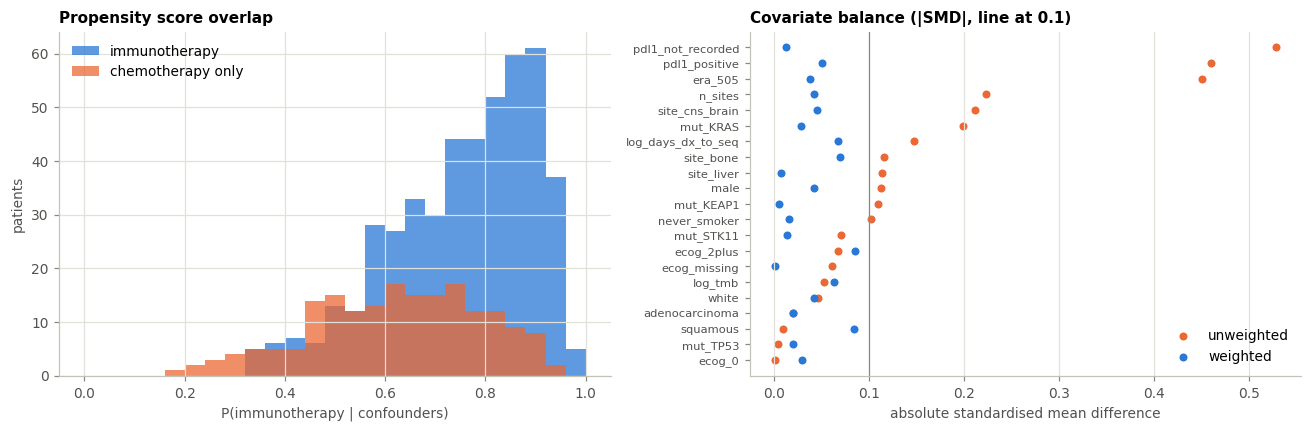

In [7]:
E = causal[causal.eligible].join(genomics[["mut_KRAS", "mut_STK11", "mut_KEAP1", "mut_TP53"]])
print(f"eligible: {len(E)} | arms: {E.regimen.value_counts().to_dict()}")

def confounders(d):
    Z = pd.DataFrame(index=d.index)
    Z["era_505"] = d.era.eq("IMPACT505").astype(float)
    Z["squamous"] = d.cancer_type_detailed.eq("Lung Squamous Cell Carcinoma").astype(float)
    Z["adenocarcinoma"] = d.cancer_type_detailed.eq("Lung Adenocarcinoma").astype(float)
    Z["male"] = d.sex.eq("Male").astype(float)
    Z["white"] = d.race.eq("White").astype(float)
    Z["never_smoker"] = d.never_smoker.fillna(d.never_smoker.mean())          # imputed without indicator
    Z["ecog_0"] = d.tz_ecog.eq(0).astype(float); Z["ecog_2plus"] = d.tz_ecog.ge(2).astype(float)
    Z["ecog_missing"] = d.tz_ecog.isna().astype(float)
    Z["pdl1_positive"] = d.tz_pdl1_positive.eq(1).astype(float); Z["pdl1_not_recorded"] = d.tz_pdl1_positive.isna().astype(float)
    for s in ["cns_brain", "liver", "bone"]:
        Z[f"site_{s}"] = d[f"tz_site_{s}"]
    Z["n_sites"] = d.tz_n_sites
    Z["log_tmb"] = np.log1p(d.tmb)
    for g in ["KRAS", "STK11", "KEAP1", "TP53"]:
        Z[f"mut_{g}"] = d[f"mut_{g}"].fillna(0)
    Z["log_days_dx_to_seq"] = np.log1p(d.dx_to_seq_days.clip(lower=0).fillna(d.dx_to_seq_days.median()))
    return Z

Z = confounders(E); A = E.treated
ps_model = sm.Logit(A, sm.add_constant(Z)).fit(disp=0, maxiter=200)
print(f"propensity model converged: {ps_model.mle_retvals['converged']} in {ps_model.mle_retvals['iterations']} iterations")
ps = ps_model.predict(sm.add_constant(Z))
print(f"propensity range: treated [{ps[A == 1].min():.2f}, {ps[A == 1].max():.2f}], chemotherapy [{ps[A == 0].min():.2f}, {ps[A == 0].max():.2f}]"
      f" | outside [0.05, 0.95]: {((ps < 0.05) | (ps > 0.95)).mean():.1%}")
w = np.where(A == 1, A.mean() / ps, (1 - A.mean()) / (1 - ps))                    # stabilised weights
ess = lambda w: w.sum() ** 2 / (w ** 2).sum()
print(f"stabilised weights: min {w.min():.2f}, max {w.max():.2f} | effective sample size: treated {ess(w[A == 1]):.0f} of {(A == 1).sum()}, chemotherapy {ess(w[A == 0]):.0f} of {(A == 0).sum()}")

def smd(Z, A, w=None):
    w = np.ones(len(A)) if w is None else w
    out = {}
    for c in Z:
        x1, x0, w1, w0 = Z[c][A == 1], Z[c][A == 0], w[A == 1], w[A == 0]
        m1, m0 = np.average(x1, weights=w1), np.average(x0, weights=w0)
        v1, v0 = np.average((x1 - m1) ** 2, weights=w1), np.average((x0 - m0) ** 2, weights=w0)
        out[c] = (m1 - m0) / np.sqrt((v1 + v0) / 2) if v1 + v0 > 0 else 0.0
    return pd.Series(out)
balance = pd.DataFrame({"unweighted": smd(Z, A), "weighted": smd(Z, A, w)}).sort_values("unweighted", key=abs)
display(balance.round(2).T)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 26)
a1.hist(ps[A == 1], bins=bins, alpha=0.75, color=SLOT[0], label="immunotherapy")
a1.hist(ps[A == 0], bins=bins, alpha=0.75, color=SLOT[1], label="chemotherapy only")
a1.set(title="Propensity score overlap", xlabel="P(immunotherapy | confounders)", ylabel="patients"); a1.legend()
y = np.arange(len(balance))
a2.scatter(balance.unweighted.abs(), y, color=SLOT[1], label="unweighted", s=18)
a2.scatter(balance.weighted.abs(), y, color=SLOT[0], label="weighted", s=18)
a2.axvline(0.1, color=MUTED, linewidth=0.8)
a2.set_yticks(y, balance.index, fontsize=7.5); a2.set(title="Covariate balance (|SMD|, line at 0.1)", xlabel="absolute standardised mean difference")
a2.grid(axis="y", visible=False); a2.legend(loc="lower right")
plt.tight_layout(); fig.savefig(FIG / "causal_overlap_balance.png", dpi=200); plt.show()